# Training data and training parameters, model by model

This notebook walks from the **raw 5-minute SPY bars** to the **exact inputs and settings** each
model was trained with. It reads only files the pipeline and the model runs already wrote
(`data/interim`, `data/processed`, `models/*/params.json`), so nothing here retrains anything.

| § | Topic |
|---|---|
| 1 | Raw data: one calm day and one crash day, bar by bar |
| 2 | From 5-minute returns to daily realized measures (RV, RS⁺, RS⁻, ΔJ²) |
| 3 | The **extension features**: downside semivariance and the signed jump, with intuition |
| 4 | How daily, weekly and monthly realized volatility are aggregated, and how the targets are built |
| 5 | Train / validation / out-of-sample splits and purging |
| 6 | **What GARCH sees vs what the RV models see** |
| 7 | GARCH(1,1)-t: what it models and how it works |
| 8 | HAR (log-OLS) |
| 9 | XGBoost (tree and linear boosters) |
| 10 | HARNet (dilated-convolution HAR) |
| 11 | Mamba and the LSTM control |
| 12 | One day, six models: the inputs side by side |

**Units used throughout.** Variance is *daily decimal variance* (e.g. RV = 1e-4). To read it as the
familiar "annualized volatility in %", use √(252 · RV) · 100, so RV = 1e-4 ≈ 15.9 %. Plots use
annualized vol so the numbers look like VIX-style levels.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")  # keep the PC responsive; nothing here is heavy
import json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import display, Markdown

from volforecast import adapters
from volforecast.config import load_config, resolve_path, PROJECT_ROOT
from volforecast.models.xgb.data import build_frames

pd.set_option("display.precision", 4); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
UP, DOWN, NEUTRAL, ACCENT = "#2a9d8f", "#d1495b", "#6c757d", "#3d5a80"

cfg = load_config()
features = adapters.load_features()
fs = features.set_index("date")
splits = {e: adapters.load_split(e) for e in ("covid", "bear2022")}
EVENTS = list(splits)
MODELS = PROJECT_ROOT / "models"

intraday = pd.read_parquet(resolve_path(cfg["paths"]["interim_5min_rth_path"]))
intraday["session_date"] = pd.to_datetime(intraday["session_date"])


def rj(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))


def ann_vol(v):
    # daily decimal variance -> annualized volatility in %
    return np.sqrt(252 * np.asarray(v, dtype=float)) * 100


print(f"feature store: {features.shape[0]:,} trading days x {features.shape[1]} columns, "
      f"{features.date.min().date()} -> {features.date.max().date()}")
print(f"5-minute RTH bars: {len(intraday):,}")

feature store: 5,720 trading days x 37 columns, 2004-01-02 -> 2026-09-30
5-minute RTH bars: 444,503


## 1. Raw data: what one trading day looks like

The source is 5-minute SPY bars from Massive (formerly Polygon), regular trading hours only
(09:30–16:00 ET), so a normal day has **78 bars**. For each bar the pipeline keeps the close and the
**5-minute log return** r = ln(close / previous close); the first bar uses its own open.

Three days for contrast:

* a quiet day in late 2019,
* **2020-03-12**, the highest-RV day of the COVID crash (the day after the WHO pandemic declaration),
* **2020-03-20**, a COVID sell-off day on which the selling happened *during* the session.

In [2]:
days = {"calm day 2019-11-15": pd.Timestamp("2019-11-15"),
        "crash day 2020-03-12": pd.Timestamp("2020-03-12"),
        "sell-off day 2020-03-20": pd.Timestamp("2020-03-20")}


def bars(day):
    g = intraday.loc[intraday.session_date == day, ["t_ny", "close", "ret_5min"]].copy()
    g["bar start (ET)"] = g.t_ny.dt.strftime("%H:%M")
    g["squared return"] = g.ret_5min ** 2
    g["sign"] = np.where(g.ret_5min > 0, "up", np.where(g.ret_5min < 0, "down", "flat"))
    return g.rename(columns={"close": "close ($)", "ret_5min": "5-min log return"})


cols = ["bar start (ET)", "close ($)", "5-min log return", "squared return", "sign"]
for label, d in days.items():
    g = bars(d)
    display(Markdown(f"**{label}**: {len(g)} bars, first and last four shown"))
    display(pd.concat([g[cols].head(4), g[cols].tail(4)]).set_index("bar start (ET)"))

**calm day 2019-11-15**: 78 bars, first and last four shown

,close ($),5-min log return,squared return,sign
bar start (ET),,,,
09:30,310.545,-1.5284e-03,2.3360e-06,down
09:35,310.560,4.8301e-05,2.3330e-09,up
09:40,310.540,-6.4402e-05,4.1476e-09,down
09:45,310.550,3.2201e-05,1.0369e-09,up
15:40,311.300,3.0522e-04,9.3158e-08,up
15:45,311.420,3.8541e-04,1.4854e-07,up
15:50,311.550,4.1736e-04,1.7419e-07,up
15:55,311.830,8.9833e-04,8.0699e-07,up


**crash day 2020-03-12**: 78 bars, first and last four shown

,close ($),5-min log return,squared return,sign
bar start (ET),,,,
09:30,255.29,-2.7773e-03,7.7133e-06,down
09:35,255.27,-7.8345e-05,6.1380e-09,down
09:40,255.27,0.0000e+00,0.0000e+00,flat
09:45,255.27,0.0000e+00,0.0000e+00,flat
15:40,251.83,5.9582e-04,3.5500e-07,up
15:45,252.70,3.4488e-03,1.1894e-05,up
15:50,252.41,-1.1483e-03,1.3185e-06,down
15:55,248.10,-1.7223e-02,2.9663e-04,down


**sell-off day 2020-03-20**: 78 bars, first and last four shown

,close ($),5-min log return,squared return,sign
bar start (ET),,,,
09:30,242.590,0.0002,6.1188e-08,up
09:35,239.880,-0.0112,1.2620e-04,down
09:40,237.880,-0.0084,7.0098e-05,down
09:45,237.410,-0.0020,3.9115e-06,down
15:40,231.560,-0.0024,5.6282e-06,down
15:45,230.020,-0.0067,4.4526e-05,down
15:50,230.135,0.0005,2.4983e-07,up
15:55,228.940,-0.0052,2.7104e-05,down


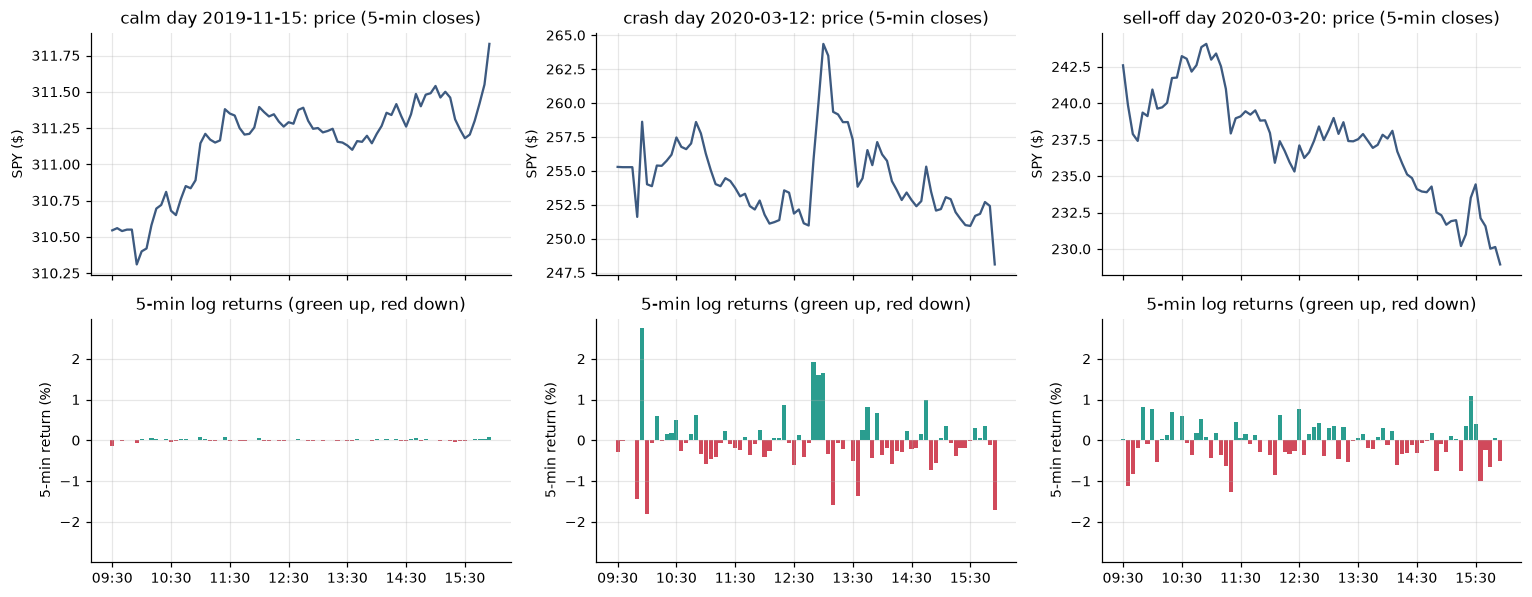

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharex="col")
for j, (label, d) in enumerate(days.items()):
    g = bars(d)
    x = np.arange(len(g))
    axes[0, j].plot(x, g["close ($)"], color=ACCENT)
    axes[0, j].set_title(f"{label}: price (5-min closes)")
    axes[0, j].set_ylabel("SPY ($)")
    r = g["5-min log return"] * 100
    axes[1, j].bar(x, r, color=np.where(r >= 0, UP, DOWN), width=0.85)
    axes[1, j].set_ylabel("5-min return (%)")
    axes[1, j].set_title("5-min log returns (green up, red down)")
    ticks = x[::12]
    axes[1, j].set_xticks(ticks, g["bar start (ET)"].iloc[::12])
# same y-scale for the returns so the size difference is visible
lim = max(max(abs(v) for v in a.get_ylim()) for a in axes[1])
for a in axes[1]:
    a.set_ylim(-lim, lim)
fig.tight_layout()

Both COVID days have bars an order of magnitude larger than the calm day. Their *direction* differs,
though. On 12 March most of the −10 % close-to-close loss had already happened **overnight** (SPY opened
about 7 % lower); during the session the price swung both ways and the day ended with one large
down bar. On 20 March the price slid from mid-morning to the close. Realized measures turn the 78 returns
into a few daily summaries that keep both kinds of information: *how much* the price moved (RV) and
*in which direction* the big moves went (the semivariances).

## 2. From 78 returns to daily realized measures

For day t with 5-minute returns r₁ … r_n (n = 78):

| Measure | Formula | Meaning |
|---|---|---|
| **RV** (realized variance) | Σ rⱼ² | total variance of the day; the target of every RV model |
| **RS⁺** (upside semivariance) | Σ rⱼ² · 1{rⱼ > 0} | variance coming from up moves |
| **RS⁻** (downside semivariance) | Σ rⱼ² · 1{rⱼ < 0} | variance coming from down moves |
| **ΔJ²** (signed jump variation) | RS⁺ − RS⁻ | positive: up moves dominated; negative: down moves dominated |
| BPV (bipower variation) | (π/2) Σ \|rⱼ\|\|rⱼ₋₁\| | jump-robust RV (stored, not used by the models) |

RS⁺ + RS⁻ = RV exactly, so the pair splits the day's variance into an "up" part and a "down" part.
Below the measures are recomputed by hand from the bars and checked against the feature store.

In [4]:
rows = []
for label, d in days.items():
    r = intraday.loc[intraday.session_date == d, "ret_5min"].to_numpy()
    by_hand = {"RV": (r ** 2).sum(), "RS+": (r[r > 0] ** 2).sum(), "RS-": (r[r < 0] ** 2).sum()}
    by_hand["dJ2 = RS+ - RS-"] = by_hand["RS+"] - by_hand["RS-"]
    stored = fs.loc[d, ["rv", "rs_pos", "rs_neg", "delta_j2"]].to_numpy()
    rows.append(pd.Series(by_hand, name=(label, "by hand")))
    rows.append(pd.Series(stored, index=by_hand.keys(), name=(label, "feature store")))
tbl = pd.DataFrame(rows)
tbl["RV as ann. vol (%)"] = ann_vol(tbl["RV"])
tbl["share of RV from down moves"] = tbl["RS-"] / tbl["RV"]
display(tbl.style.format("{:.3e}").format("{:.1f}", subset=["RV as ann. vol (%)"])
        .format("{:.0%}", subset=["share of RV from down moves"]))

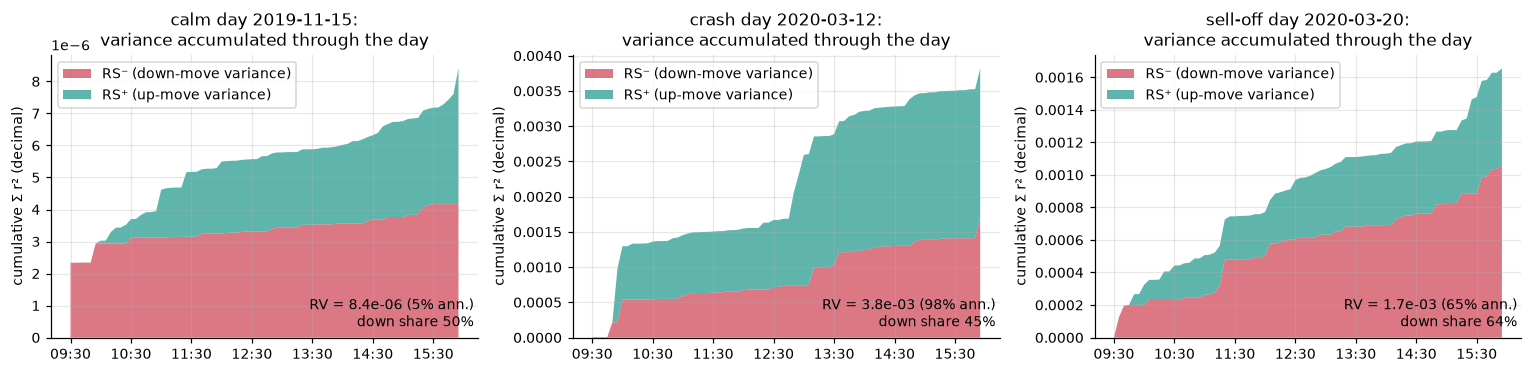

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (label, d) in zip(axes, days.items()):
    g = bars(d)
    r = g["5-min log return"].to_numpy()
    x = np.arange(len(r))
    up_c, dn_c = np.cumsum(np.where(r > 0, r ** 2, 0)), np.cumsum(np.where(r < 0, r ** 2, 0))
    ax.stackplot(x, dn_c, up_c, colors=[DOWN, UP], alpha=0.75,
                 labels=["RS⁻ (down-move variance)", "RS⁺ (up-move variance)"])
    ax.set_title(f"{label}:\nvariance accumulated through the day")
    ax.set_ylabel("cumulative Σ r² (decimal)")
    ax.set_xticks(x[::12], g["bar start (ET)"].iloc[::12])
    ax.legend(loc="upper left")
    tot = up_c[-1] + dn_c[-1]
    ax.text(0.99, 0.04, f"RV = {tot:.1e} ({ann_vol(tot):.0f}% ann.)\ndown share {dn_c[-1] / tot:.0%}",
            transform=ax.transAxes, ha="right")
fig.tight_layout()

Read each panel as the story of the day. On 12 March the up and down bands grow together (a violent
two-way session) and the down share is only 45 %: the panic was mostly in the overnight gap, which RV
does not measure. On 20 March the red band dominates (64 % down). Both days have very high RV, but
they are different stories, and the extension features in §3 exist to tell a model which one it is
looking at.

## 3. The extension (`ext`) features, intuitively

The `base` feature set only knows **how big** recent variance was. The `ext` set adds **which way**
it came from. Two ideas from the realized-volatility literature (Barndorff-Nielsen, Kinnebrock &
Shephard 2010; Patton & Sheppard 2015):

**(a) Downside semivariance RS⁻ is "bad volatility".** Variance that comes from falling prices predicts
*future* variance more strongly than variance from rising prices. This is the realized-measure version
of the **leverage effect**: falling prices raise leverage and fear, which raises future volatility.
`ext` gives the models `log_rs_neg` at the same three horizons as RV (daily, weekly, monthly).

**(b) The signed jump says whether the day was "up-driven" or "down-driven".** The raw ΔJ² = RS⁺ − RS⁻
is a tiny number whose scale moves with the level of volatility, which makes it awkward to feed a
log-scale model. The store uses the log-safe transform

$$\texttt{jump\_pct}_t = \ln\!\left(1 + \frac{\Delta J^2_t}{RV_t}\right) = \ln\!\left(\frac{2\,RS^+_t}{RV_t}\right)
= \ln\big(2 \times \text{share of the day's variance from up moves}\big).$$

So `jump_pct` is a **pure direction signal, independent of volatility level**:

| Day type | up-share RS⁺/RV | `jump_pct` |
|---|---|---|
| all variance from up moves | 100 % | ln 2 = +0.69 (the upper bound) |
| balanced day | 50 % | 0 |
| 25 % up / 75 % down | 25 % | ln 0.5 = −0.69 |
| crash-like, 10 % up | 10 % | ln 0.2 = −1.61 |

In this sample it ranges from about −1.73 to +0.61.

**The `ext` feature set** (shared by HAR and XGBoost; the sequence models and HARNet use the daily
versions, see §10–11):

| Column | Definition | In plain words |
|---|---|---|
| `log_rv_d`, `log_rv_w`, `log_rv_m` | ln RV at 1/5/22-day aggregation | how volatile: yesterday, last week, last month (= `base`) |
| `log_rs_neg` | ln RS⁻_t | how much *downside* variance today |
| `log_rs_neg_w` | ln mean(RS⁻ over t−4..t) | downside variance over the last week |
| `log_rs_neg_m` | ln mean(RS⁻ over t−21..t) | downside variance over the last month |
| `jump_pct` | ln(1 + ΔJ²_t / RV_t) | was today up-driven (>0) or down-driven (<0)? |

RS⁺ is left out on purpose: RS⁺ = RV − RS⁻, so it adds nothing once RV and RS⁻ are in.

jump_pct == ln(2 RS+/RV) on 5,714 of 5,720 days; the 6 exceptions are the lowest-RV days, where RV is clipped at the log floor: ['2013-12-24', '2016-11-25', '2017-08-07', '2017-11-24', '2017-12-28', '2025-12-24']
jump_pct range in sample: -1.73 to 0.61


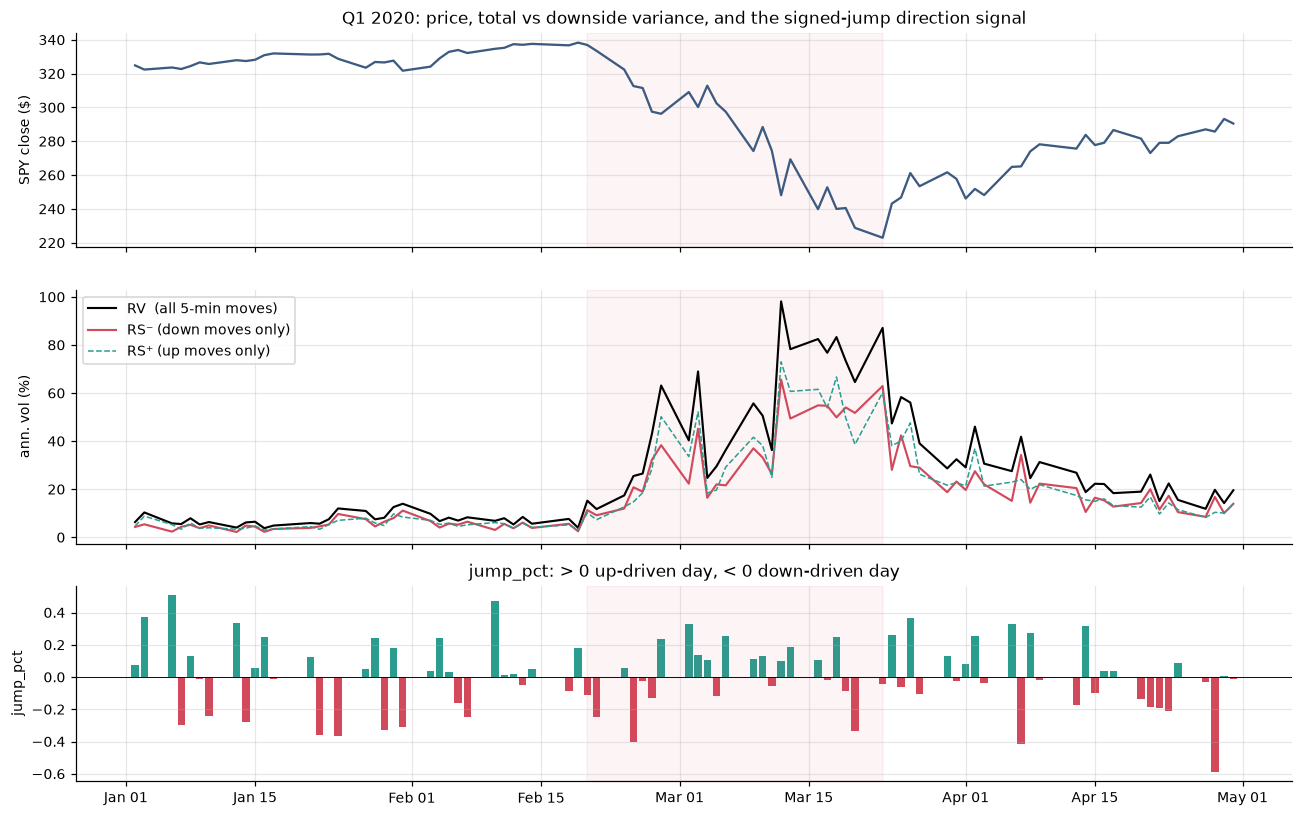

In [6]:
# jump_pct really is ln(2 * up-share)
chk = (np.log(2 * features.rs_pos / features.rv) - features.jump_pct).abs()
print(f"jump_pct == ln(2 RS+/RV) on {(chk < 1e-9).sum():,} of {len(chk):,} days; the {(chk >= 1e-9).sum()} exceptions are "
      f"the lowest-RV days, where RV is clipped at the log floor: {[str(d.date()) for d in features.date[chk >= 1e-9]]}")
print(f"jump_pct range in sample: {features.jump_pct.min():.2f} to {features.jump_pct.max():.2f}")

w = fs.loc["2020-01-02":"2020-04-30"]
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, height_ratios=[1.1, 1.3, 1])
axes[0].plot(w.index, w.daily_close, color=ACCENT); axes[0].set_ylabel("SPY close ($)")
axes[0].set_title("Q1 2020: price, total vs downside variance, and the signed-jump direction signal")
axes[1].plot(w.index, ann_vol(w.rv), color="black", lw=1.4, label="RV  (all 5-min moves)")
axes[1].plot(w.index, ann_vol(w.rs_neg), color=DOWN, lw=1.4, label="RS⁻ (down moves only)")
axes[1].plot(w.index, ann_vol(w.rs_pos), color=UP, lw=1, ls="--", label="RS⁺ (up moves only)")
axes[1].set_ylabel("ann. vol (%)"); axes[1].legend(loc="upper left")
axes[2].bar(w.index, w.jump_pct, color=np.where(w.jump_pct >= 0, UP, DOWN), width=0.8)
axes[2].axhline(0, color="black", lw=0.6)
axes[2].set_ylabel("jump_pct"); axes[2].set_title("jump_pct: > 0 up-driven day, < 0 down-driven day")
for a in axes:
    a.axvspan(pd.Timestamp(splits["covid"]["event"]["start"]), pd.Timestamp(splits["covid"]["event"]["end"]),
              color=DOWN, alpha=0.06)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()

What this shows about COVID, honestly: the in-session down share was **only modestly above 50 %**
during the crash. RS⁺ (dashed) is often as large as RS⁻ because the market rebounded violently within
the day, and many of the biggest losses came as overnight gaps, which RTH semivariances do not see.
`jump_pct` was clearly negative on a few early days (21, 25 and 27 Feb; 20 Mar) but mixed overall. So
the `ext` direction signal was weaker in this event than in an average sell-off, which is worth keeping
in mind for sub-question 2.

Does the direction signal predict anything *beyond* the RV level? A naive comparison is misleading,
since down-driven days also tend to be high-RV days, after which variance mean-reverts. So, on
**pre-COVID data only** (2004 → 2019), we first fit the base HAR (log RV d/w/m) and then ask:
sorting days into five groups by `jump_pct`, does the base HAR systematically **under**-forecast after
down-driven days? A positive mean residual means future variance came in higher than RV alone predicted.

,mean_jump_pct,mean_up_share,days,h=1,h=5,h=22
jump_pct quintile,,,,,,
Q1 most down-driven,-0.42,33%,801,+0.138,+0.089,+0.044
Q2,-0.14,44%,801,-0.009,-0.008,-0.004
Q3,+0.01,50%,800,-0.026,-0.019,-0.015
Q4,+0.14,57%,801,-0.052,-0.021,-0.015
Q5 most up-driven,+0.32,69%,801,-0.051,-0.041,-0.009


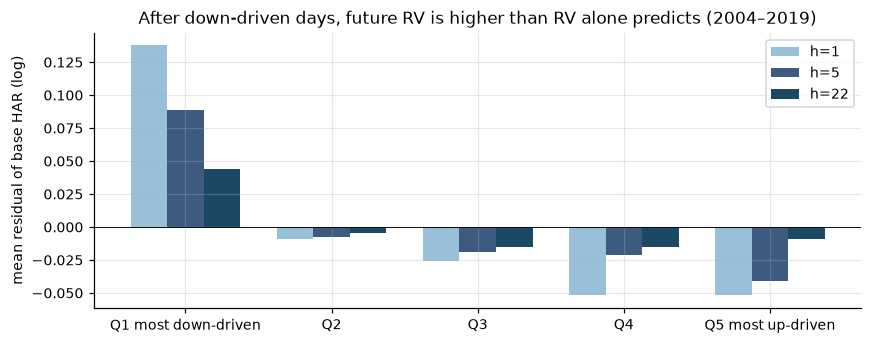

In [7]:
import statsmodels.api as sm
pre = features[features.date <= "2019-12-31"].dropna(subset=["log_rv_m", "jump_pct", "y_h22"]).copy()
labels = ["Q1 most down-driven", "Q2", "Q3", "Q4", "Q5 most up-driven"]
pre["jump_pct quintile"] = pd.qcut(pre.jump_pct, 5, labels=labels)
resid = {}
for h in (1, 5, 22):
    fit = sm.OLS(pre[f"y_h{h}"], sm.add_constant(pre[adapters.FEATURE_SETS["base"]])).fit()
    resid[f"h={h}"] = fit.resid.groupby(pre["jump_pct quintile"], observed=True).mean()
resid = pd.DataFrame(resid)
info = pre.groupby("jump_pct quintile", observed=True).agg(
    mean_jump_pct=("jump_pct", "mean"), mean_up_share=("rs_pos", lambda s: (s / pre.loc[s.index, "rv"]).mean()),
    days=("rv", "size"))
display(info.join(resid).style.format({"mean_jump_pct": "{:+.2f}", "mean_up_share": "{:.0%}",
                                        "h=1": "{:+.3f}", "h=5": "{:+.3f}", "h=22": "{:+.3f}"})
        .set_caption("Mean base-HAR residual (log points) by jump_pct quintile, 2004-2019"))

fig, ax = plt.subplots(figsize=(8, 3.2))
resid.plot.bar(ax=ax, color=["#98c1d9", "#3d5a80", "#1b4965"], width=0.75)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("mean residual of base HAR (log)"); ax.set_xlabel("")
ax.set_title("After down-driven days, future RV is higher than RV alone predicts (2004–2019)")
plt.setp(ax.get_xticklabels(), rotation=0)
fig.tight_layout()

After the most down-driven fifth of days, next-day variance is about 15 % (e^0.14 − 1) higher than a
base HAR predicts and next-week variance about 9 % higher; after up-driven days it is a few percent
lower. The effect fades with the horizon. That asymmetry, the **leverage effect** in realized form, is
what `log_rs_neg*` and `jump_pct` let a model use and what `base` cannot see.

## 4. Aggregating realized volatility over horizons

### 4.1 Backward-looking features: daily, weekly, monthly

The HAR idea (Corsi 2009): volatility is driven by traders with different horizons, so give the
model the recent variance averaged over **1 day, 1 week (5 trading days) and 1 month (22 trading days)**:

$$RV^{(d)}_t = RV_t,\qquad RV^{(w)}_t = \tfrac15\sum_{i=0}^{4} RV_{t-i},\qquad RV^{(m)}_t = \tfrac1{22}\sum_{i=0}^{21} RV_{t-i}$$

and the features are their logs: `log_rv_d`, `log_rv_w`, `log_rv_m`. Three details matter:

1. **Variances are averaged, then logged** (not an average of logs). Averaging variance is the right
   way to add up risk over days. The log is applied afterwards, because log RV is close to Gaussian
   and turns the multiplicative dynamics into additive ones, which suits linear models.
2. The windows **include day t** (known at the close of t). Nothing from t+1 or later is used.
3. The same 1/5/22 averaging is applied to RS⁻ for `log_rs_neg_w` and `log_rs_neg_m`.

Below, the averages are recomputed by hand for one date and checked against the store.

In [8]:
T = pd.Timestamp("2020-02-28")
pos = fs.index.get_loc(T)
win = fs.iloc[pos - 21: pos + 1][["rv", "rs_neg"]].copy()
win.insert(0, "days back", np.arange(21, -1, -1))
win["in weekly window"] = win["days back"] <= 4
win["in monthly window"] = True
display(Markdown(f"**The 22 trading days ending {T.date()}** (the monthly window); the last five form the weekly window"))
display(win.tail(8).style.format({"rv": "{:.3e}", "rs_neg": "{:.3e}"}))

by_hand = {
    "log_rv_d": np.log(win.rv.iloc[-1]),
    "log_rv_w": np.log(win.rv.iloc[-5:].mean()),
    "log_rv_m": np.log(win.rv.mean()),
    "log_rs_neg": np.log(win.rs_neg.iloc[-1]),
    "log_rs_neg_w": np.log(win.rs_neg.iloc[-5:].mean()),
    "log_rs_neg_m": np.log(win.rs_neg.mean()),
}
chk = pd.DataFrame({"by hand": by_hand, "feature store": fs.loc[T, list(by_hand)]})
chk["as ann. vol (%)"] = ann_vol(np.exp(chk["by hand"]))
display(chk)

**The 22 trading days ending 2020-02-28** (the monthly window); the last five form the weekly window

,days back,rv,rs_neg,in weekly window,in monthly window
date,,,,,
2020-02-19 00:00:00,7,6.189e-06,2.479e-06,False,True
2020-02-20 00:00:00,6,9.203e-05,5.088e-05,False,True
2020-02-21 00:00:00,5,5.479e-05,3.342e-05,False,True
2020-02-24 00:00:00,4,1.206e-04,5.686e-05,True,True
2020-02-25 00:00:00,3,2.579e-04,1.718e-04,True,True
2020-02-26 00:00:00,2,2.791e-04,1.427e-04,True,True
2020-02-27 00:00:00,1,7.323e-04,4.117e-04,True,True
2020-02-28 00:00:00,0,1.582e-03,5.825e-04,True,True


,by hand,feature store,as ann. vol (%)
log_rv_d,-6.4490,-6.4490,63.1432
log_rv_w,-7.4279,-7.4279,38.7032
log_rv_m,-8.7346,-8.7346,20.1371
log_rs_neg,-7.4482,-7.4482,38.3134
log_rs_neg_w,-8.2056,-8.2056,26.2345
log_rs_neg_m,-9.4896,-9.4896,13.8060


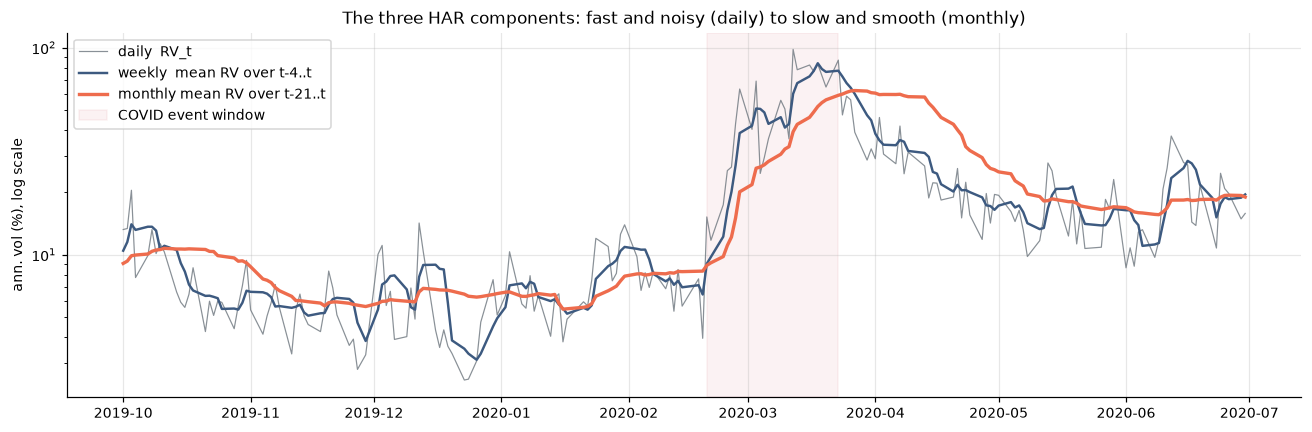

In [9]:
w = fs.loc["2019-10-01":"2020-06-30"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.index, ann_vol(np.exp(w.log_rv_d)), color=NEUTRAL, lw=0.8, alpha=0.8, label="daily  RV_t")
ax.plot(w.index, ann_vol(np.exp(w.log_rv_w)), color=ACCENT, lw=1.6, label="weekly  mean RV over t-4..t")
ax.plot(w.index, ann_vol(np.exp(w.log_rv_m)), color="#ee6c4d", lw=2.2, label="monthly mean RV over t-21..t")
ax.axvspan(pd.Timestamp(splits["covid"]["event"]["start"]), pd.Timestamp(splits["covid"]["event"]["end"]),
           color=DOWN, alpha=0.07, label="COVID event window")
ax.set_yscale("log"); ax.set_ylabel("ann. vol (%), log scale")
ax.set_title("The three HAR components: fast and noisy (daily) to slow and smooth (monthly)")
ax.legend(loc="upper left")
fig.tight_layout()

The daily line reacts first but is noisy; the monthly line is smooth but lags by weeks and stays
high long after the trough. A forecasting model's job is to weigh the three, and the early-warning
question is largely about **how much weight goes on the fast component**.

### 4.2 Forward-looking targets

Every RV model forecasts the **mean variance over the next h trading days** directly (one model per
horizon, no recursion):

$$\texttt{rv\_h}\{h\}_t = \tfrac1h\sum_{i=1}^{h} RV_{t+i},\qquad \texttt{y\_h}\{h\}_t = \ln \texttt{rv\_h}\{h\}_t,\qquad h \in \{1, 5, 22\}.$$

So h = 5 is "average variance over the coming week" and h = 22 "over the coming month". HAR, XGBoost and
the sequence models fit the log target `y_h{h}`; HARNet fits the level `rv_h{h}`; GARCH never sees
these targets at all (§6).

**One row, origin 2020-02-21** (two days before the first big COVID sell-off):

,log value,as ann. vol (%),kind
log_rv_d,-9.8120,11.7501,feature
log_rv_w,-10.1838,9.7572,feature
log_rv_m,-10.3129,9.1469,feature
y_h1,-9.0231,17.4324,target
y_h5,-7.4279,38.7032,target
y_h22,-6.5609,59.7068,target


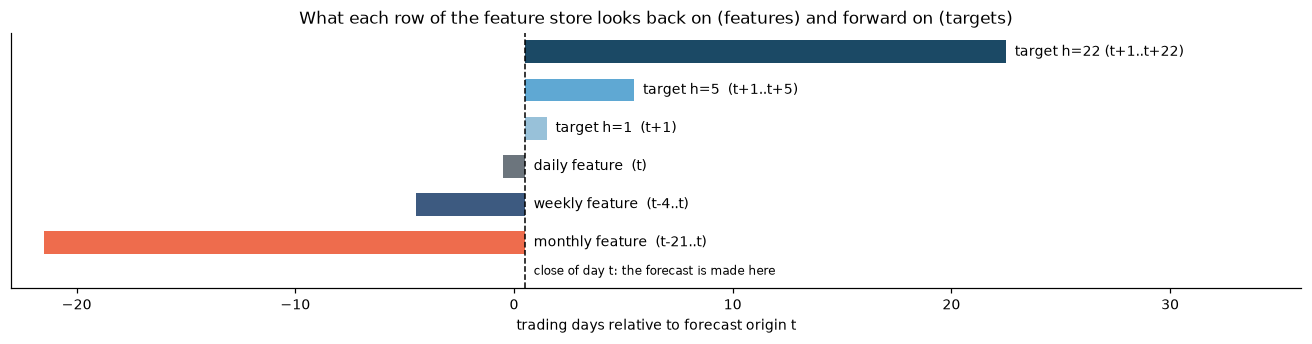

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.2))
rows_ = [("monthly feature  (t-21..t)", -21, 0, "#ee6c4d"), ("weekly feature  (t-4..t)", -4, 0, ACCENT),
         ("daily feature  (t)", 0, 0, NEUTRAL),
         ("target h=1  (t+1)", 1, 1, "#98c1d9"), ("target h=5  (t+1..t+5)", 1, 5, "#5fa8d3"),
         ("target h=22 (t+1..t+22)", 1, 22, "#1b4965")]
for k, (lab, a, b, c) in enumerate(rows_):
    ax.barh(k, b - a + 1, left=a - 0.5, color=c, height=0.6)
    ax.text(b + 0.9 if b >= 0 else a - 1, k, lab, va="center", ha="left", fontsize=9)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.text(0.9, -0.85, "close of day t: the forecast is made here", fontsize=8)
ax.set_ylim(-1.2, len(rows_) - 0.5)
ax.set_yticks([]); ax.set_xlim(-23, 36); ax.set_xlabel("trading days relative to forecast origin t")
ax.set_title("What each row of the feature store looks back on (features) and forward on (targets)")
ax.grid(False)
fig.tight_layout()

T = pd.Timestamp("2020-02-21")
cols = ["log_rv_d", "log_rv_w", "log_rv_m", "y_h1", "y_h5", "y_h22"]
row = fs.loc[T, cols]
display(Markdown(f"**One row, origin {T.date()}** (two days before the first big COVID sell-off):"))
display(pd.DataFrame({"log value": row, "as ann. vol (%)": ann_vol(np.exp(row)),
                      "kind": ["feature"] * 3 + ["target"] * 3}))

On 21 Feb 2020 every backward-looking feature said ≈ 10–12 % vol; the next-month target turned out to
be ≈ 60 %. That gap is what the event study measures.

## 5. Training windows, splits and purging

Each event has its own split. Models are tuned on the **validation** block, then **refit on train +
validation** and frozen at the cutoff; after the cutoff they only forecast.

**Purging.** A training row at day t has a target that looks at t+1..t+h. If that window crosses into
the next block, the row would leak future information, so it is dropped. That is why the last usable
training row moves earlier as h grows (22 days earlier for h = 22).

train rows train ends (purged)  val rows val ends (purged)  refit rows (train+val) cutoff (frozen)  out-of-sample days
event    h                                                                                                                         
covid    1         3601          2018-05-24       401        2019-12-30                    4003      2019-12-31                 441
         5         3597          2018-05-18       397        2019-12-23                    3999      2019-12-31                 441
         22        3580          2018-04-25       380        2019-11-27                    3982      2019-12-31                 441
bear2022 1         3997          2019-12-19       446        2021-09-29                    4444      2021-09-30                 877
         5         3993          2019-12-13       442        2021-09-23                    4440      2021-09-30                 877
         22        3976          2019-11-19       425        2021-08-30                    4423      2021-09-30                 877

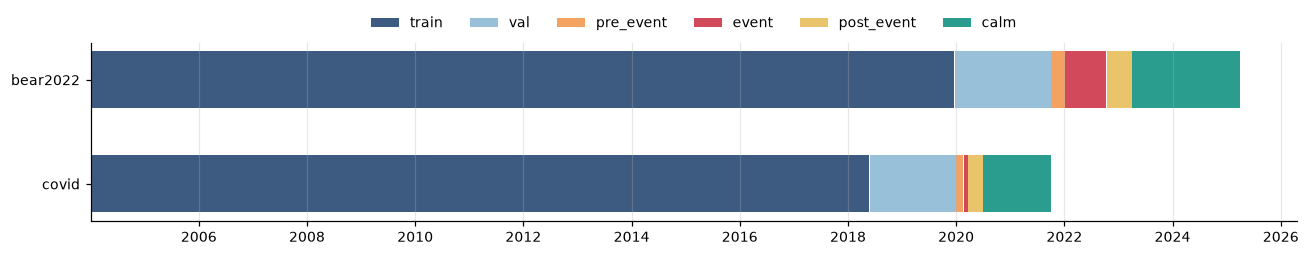

In [11]:
seg_colors = {"train": "#3d5a80", "val": "#98c1d9", "pre_event": "#f4a261", "event": DOWN,
              "post_event": "#e9c46a", "calm": UP}
fig, ax = plt.subplots(figsize=(12, 2.4))
for k, e in enumerate(EVENTS):
    s = splits[e]
    for seg, c in seg_colors.items():
        a, b = pd.Timestamp(s[seg]["start"]), pd.Timestamp(s[seg]["end"])
        ax.barh(k, (b - a).days, left=a, color=c, height=0.55, label=seg if k == 0 else None)
ax.set_yticks(range(len(EVENTS)), EVENTS); ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
fig.tight_layout()

rows = []
for e in EVENTS:
    s = splits[e]
    for h in (1, 5, 22):
        fr = build_frames(features, s, adapters.FEATURE_SETS["ext"], h)
        rows.append({"event": e, "h": h,
                     "train rows": len(fr.train), "train ends (purged)": s["train"]["end_by_horizon"][str(h)],
                     "val rows": len(fr.val), "val ends (purged)": s["val"]["end_by_horizon"][str(h)],
                     "refit rows (train+val)": len(fr.refit), "cutoff (frozen)": str(fr.cutoff.date()),
                     "out-of-sample days": len(fr.oos)})
display(pd.DataFrame(rows).set_index(["event", "h"]))

Two things to keep in mind when reading results: the **2022 validation block contains COVID**, and,
because of the refit, the 2022 models were trained on COVID while the COVID models never saw a crash of
that speed (the closest in their training data is 2008).

## 6. What GARCH sees vs what the RV models see

This is the most important difference between the baseline and everything else.

| | GARCH | RV models (HAR, XGBoost, HARNet, Mamba/LSTM) |
|---|---|---|
| Raw input | **one number per day**: the close-to-close log return `ret_cc_pct` (in %) | **78 numbers per day**, summarized into RV, RS⁻, ΔJ² |
| Time covered | 16:00 yesterday → 16:00 today, **overnight gap included** | 09:30 → 16:00 only (regular hours) |
| How it "measures" variance | it never observes variance; it *infers* it from the size of daily returns | variance is **measured** each day from intraday data |
| Training target | none: maximum likelihood of the returns themselves | future realized variance `y_h{h}` / `rv_h{h}` |
| Direction information | none in GARCH(1,1) (a +3 % and −3 % day have the same effect) | `ext`: RS⁻ and the signed jump |

The close-to-close return splits into an overnight part and a trading-hours part:
ret_cc ≈ ret_overnight + oc_return. RV only measures the second piece.

In [12]:
T = pd.Timestamp("2020-03-12")
r = fs.loc[T]
display(Markdown(f"**{T.date()}: the two models' raw input for the same day**"))
display(pd.DataFrame({
    "value": [r.ret_cc_pct, r.ret_overnight * 100, r.oc_return * 100, (r.ret_cc_pct) ** 2,
              r.rv * 1e4, r.rs_neg * 1e4, r.jump_pct],
    "fed to": ["GARCH", "(part of ret_cc)", "(part of ret_cc)", "GARCH implicitly (r² drives σ²)",
               "RV models", "RV models, ext", "RV models, ext"],
}, index=["ret_cc_pct  (close-to-close return, %)", "overnight return (%)", "open-to-close return (%)",
          "squared return (%²)", "RV (%², ×1e4)", "RS⁻ (%², ×1e4)", "jump_pct"]))

**2020-03-12: the two models' raw input for the same day**

,value,fed to
"ret_cc_pct (close-to-close return, %)",-10.0569,GARCH
overnight return (%),-6.9264,(part of ret_cc)
open-to-close return (%),-3.1346,(part of ret_cc)
squared return (%²),101.1411,GARCH implicitly (r² drives σ²)
"RV (%², ×1e4)",38.2144,RV models
"RS⁻ (%², ×1e4)",17.0684,"RV models, ext"
jump_pct,0.1014,"RV models, ext"


,rank corr. with next-month RV (2004-2019)
r² today,0.3501
RV today,0.6659
RV monthly mean,0.6619


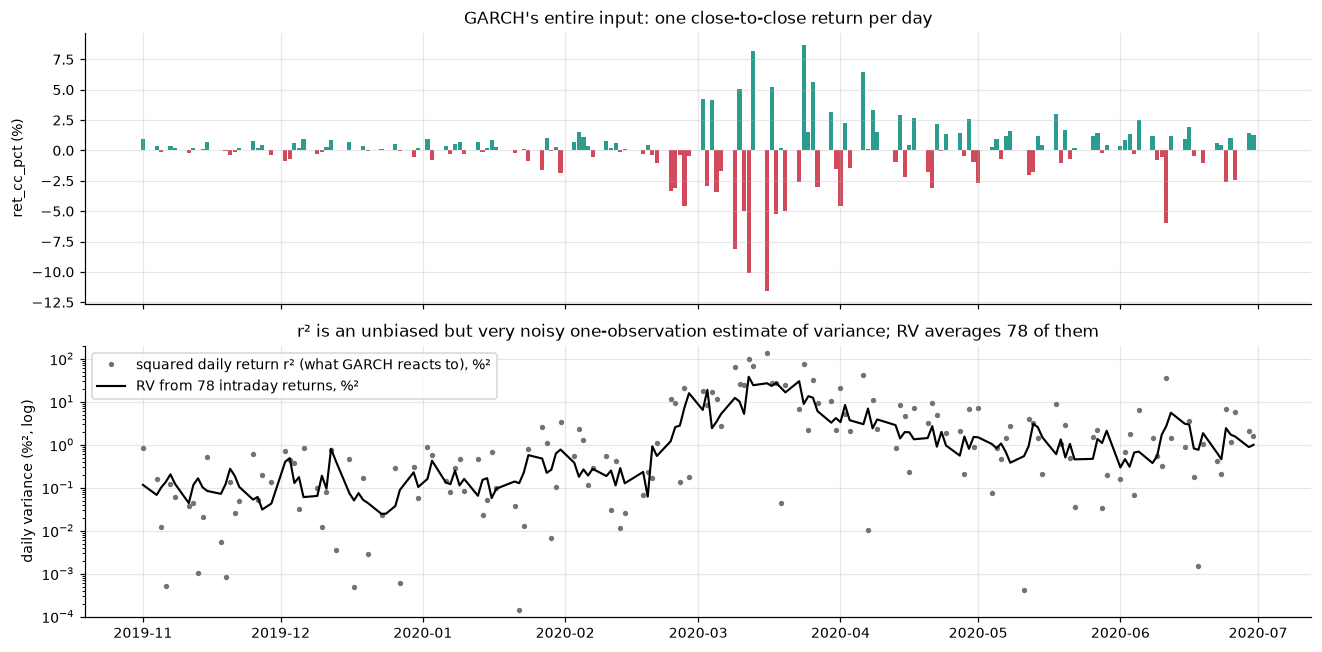

In [13]:
w = fs.loc["2019-11-01":"2020-06-30"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].bar(w.index, w.ret_cc_pct, color=np.where(w.ret_cc_pct >= 0, UP, DOWN), width=0.9)
axes[0].set_ylabel("ret_cc_pct (%)")
axes[0].set_title("GARCH's entire input: one close-to-close return per day")
axes[1].plot(w.index, w.ret_cc_pct ** 2, color=NEUTRAL, lw=0, marker="o", ms=2.5,
             label="squared daily return r² (what GARCH reacts to), %²")
axes[1].plot(w.index, w.rv * 1e4, color="black", lw=1.4, label="RV from 78 intraday returns, %²")
axes[1].set_yscale("log"); axes[1].set_ylim(1e-4, 200)
axes[1].set_ylabel("daily variance (%², log)")
axes[1].set_title("r² is an unbiased but very noisy one-observation estimate of variance; RV averages 78 of them")
axes[1].legend(loc="upper left")
fig.tight_layout()

pre = features[features.date <= "2019-12-31"].dropna(subset=["rv_h22", "ret_cc_pct"])
rho = pre[["rv_h22"]].assign(**{"r² today": pre.ret_cc_pct ** 2, "RV today": pre.rv,
                                 "RV monthly mean": np.exp(pre.log_rv_m)}).corr("spearman")["rv_h22"].drop("rv_h22")
display(rho.rename("rank corr. with next-month RV (2004-2019)").to_frame())

Note the 12 March row: GARCH sees a −10 % day (r² ≈ 101 %²), while the RV models see RTH variance of
38 %² with a slightly *up*-driven session, because 7 points of the drop happened overnight. Neither view
is wrong; they measure different windows of the same day.

On calm days r² swings over several orders of magnitude (a day that happens to close unchanged gives
r² ≈ 0 even if the market moved a lot intraday), while RV is stable. That is why RV-based models
usually forecast better: they observe variance far more precisely. GARCH compensates by averaging
many past squared returns through its recursion (next section), which makes it smooth but slow.

## 7. GARCH(1,1)-t: what it models and how it works

### The idea

Daily returns are almost unpredictable in **direction**, but their **size** clusters: big moves follow
big moves, calm follows calm. GARCH (Engle 1982; Bollerslev 1986) models exactly that. Each day's return
is a random shock scaled by a volatility that changes over time:

$$r_t = \mu + \varepsilon_t,\qquad \varepsilon_t = \sigma_t z_t,\qquad z_t \sim \text{Student-}t_\nu \text{ (scaled to variance 1)}$$

and the variance for tomorrow is updated every evening by one simple rule:

$$\boxed{\sigma^2_{t+1} = \omega + \alpha\,\varepsilon_t^2 + \beta\,\sigma_t^2}$$

Read it as **"tomorrow's variance = a floor + a reaction to today's surprise + memory of today's variance"**:

| Parameter | Role | Intuition |
|---|---|---|
| ω | constant | keeps variance positive and sets the long-run level |
| α | **news / shock reaction** | how much one big return today raises tomorrow's variance |
| β | **memory** | how much of today's variance level carries over |
| α + β | **persistence** | close to 1 ⇒ volatility shocks die out slowly |
| ω / (1 − α − β) | **long-run variance** σ̄² | where variance drifts back to when nothing happens |
| ν | Student-t degrees of freedom | fat tails: a 5σ day is far more likely than under a normal |

### Forecasting = mean reversion

Taking expectations, k steps ahead the forecast decays geometrically towards σ̄²:

$$E_t[\sigma^2_{t+k}] = \bar\sigma^2 + (\alpha+\beta)^{k-1}\big(\sigma^2_{t+1} - \bar\sigma^2\big).$$

The h-day forecast stored for the study is the mean of steps 1..h (to match the RV targets), divided
by 10⁴ to turn %² into decimal variance, and multiplied by a scale factor c so it is on the
regular-hours RV level (§6: GARCH variance includes the overnight gap).

### How it is fit

Not by regression on a target. The parameters (μ, ω, α, β, ν) are chosen to **maximize the
likelihood of the observed returns**: a good model makes big returns happen on days when it already
predicted high σ. Fit once on 2004 → cutoff, then frozen. No feature sets, no hyperparameter search.

In [14]:
gp = {e: rj(MODELS / "garch" / e / "params.json") for e in EVENTS}
rows = {}
for e, p in gp.items():
    q = p["params"]; pers = q["alpha[1]"] + q["beta[1]"]
    lr_var = q["omega"] / (1 - pers)  # %^2 per day
    rows[e] = {
        "fit window": " → ".join(p["fit_range"]), "observations": p["n_obs"],
        "μ (daily mean return, %)": q["mu"], "ω": q["omega"], "α (shock reaction)": q["alpha[1]"],
        "β (memory)": q["beta[1]"], "α + β (persistence)": pers,
        "half-life of a shock (days)": np.log(0.5) / np.log(pers),
        "long-run vol, close-to-close (ann. %)": np.sqrt(252 * lr_var),
        "ν (Student-t dof)": q["nu"], "scale c = mean RV / mean GARCH var": p["rv_scale_c"],
        "log-likelihood": p["loglik"],
    }
display(Markdown("**Frozen GARCH(1,1)-t parameters** (`models/garch/{event}/params.json`; spec from `configs/garch.yaml`)"))
display(pd.DataFrame(rows))

**Frozen GARCH(1,1)-t parameters** (`models/garch/{event}/params.json`; spec from `configs/garch.yaml`)

,covid,bear2022
fit window,2004-01-02 → 2019-12-31,2004-01-02 → 2021-09-30
observations,4024,4465
"μ (daily mean return, %)",0.0799,0.0849
ω,0.0164,0.0198
α (shock reaction),0.1314,0.1442
β (memory),0.8617,0.8483
α + β (persistence),0.9931,0.9925
half-life of a shock (days),100.4424,92.176
"long-run vol, close-to-close (ann. %)",24.4948,25.7878
ν (Student-t dof),5.4238,5.4135


**Reading the numbers.** α ≈ 0.13 and β ≈ 0.86: one day's surprise moves tomorrow's variance a bit, and
86 % of today's variance carries over. Persistence ≈ 0.993 means a shock loses half its effect only after
roughly 100 trading days, which is why GARCH stays elevated for months after a crash. ν ≈ 5.4 is a
very fat-tailed distribution. c ≈ 0.58: regular-hours variance is about 58 % of close-to-close
variance, so the overnight gap carries roughly 40 % of daily risk for SPY.

### The recursion in action

Below the frozen COVID parameters are run through late February 2020, by hand, one day at a time,
and the result is checked against the `arch` library. Each column of the update rule is shown
separately so you can see **what moved the forecast**.

In [15]:
from arch import arch_model

e = "covid"; spec = rj(PROJECT_ROOT / "models" / "garch" / e / "params.json")["spec"]
q = pd.Series(gp[e]["params"])
returns = fs.ret_cc_pct.dropna()
am = arch_model(returns, mean=spec["mean"], vol=spec["vol"], p=spec["p"], o=spec["o"], q=spec["q"],
                dist=spec["dist"], rescale=False)
fixed = am.fix(q.values)                        # frozen parameters, filtered over the whole series
sigma2 = fixed.conditional_volatility ** 2      # sigma_t^2: variance for day t, known at the close of t-1

w = pd.DataFrame({"r_t (%)": returns, "σ²_t (%²)": sigma2}).loc["2020-02-14":"2020-03-13"]
w["ε²_t = (r_t − μ)²"] = (w["r_t (%)"] - q["mu"]) ** 2
w["ω"] = q["omega"]
w["α·ε²_t  (reaction)"] = q["alpha[1]"] * w["ε²_t = (r_t − μ)²"]
w["β·σ²_t  (memory)"] = q["beta[1]"] * w["σ²_t (%²)"]
w["σ²_t+1 by hand"] = w["ω"] + w["α·ε²_t  (reaction)"] + w["β·σ²_t  (memory)"]
w["σ²_t+1 from arch"] = sigma2.shift(-1).reindex(w.index)
w["→ ann. vol for t+1 (%)"] = np.sqrt(252 * w["σ²_t+1 by hand"])
print("max |by hand - arch| =", f'{(w["σ²_t+1 by hand"] - w["σ²_t+1 from arch"]).abs().max():.1e}')
w.index = w.index.date
display(w.drop(columns=["ω", "σ²_t+1 from arch"]).style.format("{:.3f}")
        .background_gradient(subset=["α·ε²_t  (reaction)"], cmap="Reds")
        .set_caption(f"ω = {q['omega']:.4f} added every day; units are %² per day"))

max |by hand - arch| = 1.4e-14


,r_t (%),σ²_t (%²),ε²_t = (r_t − μ)²,α·ε²_t (reaction),β·σ²_t (memory),σ²_t+1 by hand,→ ann. vol for t+1 (%)
2020-02-14,0.160,0.636,0.006,0.001,0.548,0.565,11.936
2020-02-18,-0.258,0.565,0.114,0.015,0.487,0.519,11.432
2020-02-19,0.477,0.519,0.158,0.021,0.447,0.484,11.043
2020-02-20,-0.412,0.484,0.242,0.032,0.417,0.465,10.827
2020-02-21,-1.035,0.465,1.243,0.163,0.401,0.581,12.096
2020-02-24,-3.373,0.581,11.921,1.567,0.500,2.084,22.915
2020-02-25,-3.077,2.084,9.967,1.310,1.795,3.122,28.049
2020-02-26,-0.369,3.122,0.201,0.026,2.690,2.733,26.243
2020-02-27,-4.595,2.733,21.856,2.873,2.355,5.244,36.353
2020-02-28,-0.421,5.244,0.251,0.033,4.519,4.568,33.929


On calm days (mid-February) the "memory" term is almost all of tomorrow's variance and the forecast
barely moves. From 24 February the reaction term jumps with each large return, and the memory term
then carries that increase forward. GARCH needs **several** big days in a row before its forecast gets
high, because a single r² only enters with weight α ≈ 0.13.

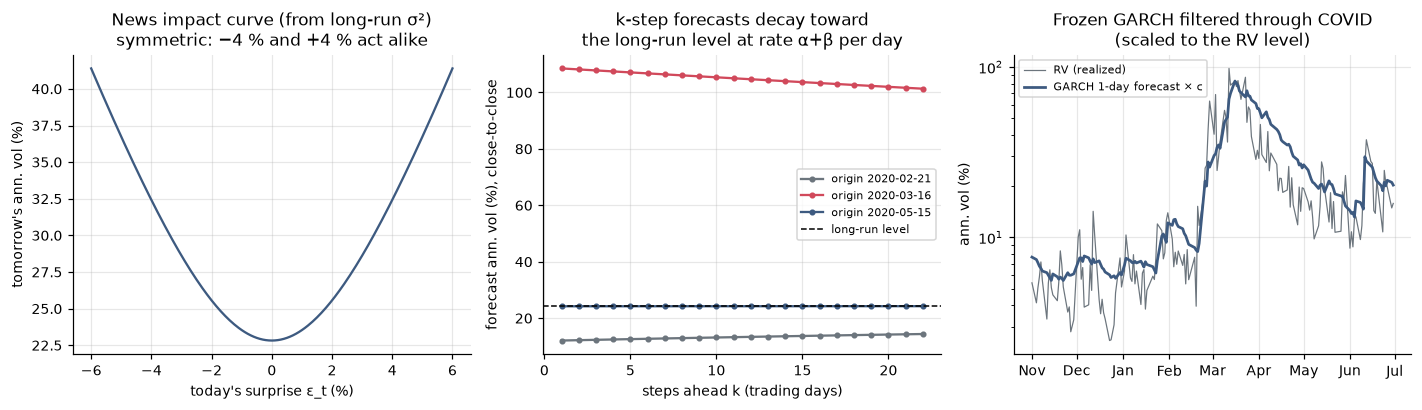

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# (a) news impact curve: symmetric in the sign of the shock
eps = np.linspace(-6, 6, 241)
base_s2 = float(q["omega"] / (1 - q["alpha[1]"] - q["beta[1]"]))
nic = q["omega"] + q["alpha[1]"] * eps ** 2 + q["beta[1]"] * base_s2
axes[0].plot(eps, np.sqrt(252 * nic), color=ACCENT)
axes[0].set_xlabel("today's surprise ε_t (%)"); axes[0].set_ylabel("tomorrow's ann. vol (%)")
axes[0].set_title("News impact curve (from long-run σ²)\nsymmetric: −4 % and +4 % act alike")

# (b) mean reversion of the forecast from several origins
c = gp[e]["rv_scale_c"]
for d, col in [("2020-02-21", NEUTRAL), ("2020-03-16", DOWN), ("2020-05-15", ACCENT)]:
    path = fixed.forecast(horizon=22, start=pd.Timestamp(d), reindex=False, method="analytic").variance.iloc[0]
    axes[1].plot(range(1, 23), np.sqrt(252 * path.to_numpy()), marker="o", ms=3, color=col, label=f"origin {d}")
axes[1].axhline(np.sqrt(252 * base_s2), color="black", ls="--", lw=1, label="long-run level")
axes[1].set_xlabel("steps ahead k (trading days)"); axes[1].set_ylabel("forecast ann. vol (%), close-to-close")
axes[1].set_title("k-step forecasts decay toward\nthe long-run level at rate α+β per day"); axes[1].legend(fontsize=7)

# (c) filtered 1-step variance vs RV through COVID
ww = fs.loc["2019-11-01":"2020-06-30"]
s2n = sigma2.shift(-1).reindex(ww.index) / 1e4   # forecast for t+1 made at t, decimal
axes[2].plot(ww.index, ann_vol(ww.rv), color=NEUTRAL, lw=0.8, label="RV (realized)")
axes[2].plot(ww.index, ann_vol(c * s2n), color=ACCENT, lw=1.8, label="GARCH 1-day forecast × c")
axes[2].set_yscale("log"); axes[2].set_ylabel("ann. vol (%)"); axes[2].legend(fontsize=7)
axes[2].set_title("Frozen GARCH filtered through COVID\n(scaled to the RV level)")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.tight_layout()

**Take-aways for the comparison.**

* GARCH learns *only* from the size of daily close-to-close returns; it has no intraday information and
  no notion of direction (the news impact curve is a symmetric parabola). The `ext` RV models get the
  asymmetry explicitly from RS⁻ and `jump_pct`. A GJR-GARCH (`o: 1` in `configs/garch.yaml`) would add a
  leverage term and is listed as an optional robustness check.
* Its forecast rises only as fast as α lets single returns move it, and then decays very slowly
  (persistence 0.993). Expect a late but long-lasting warning.
* Its overnight-inclusive variance is rescaled by c for level comparisons; lift-based warning metrics do
  not depend on c.

## 8. HAR (log-OLS)

**Training data.** The tabular view: one row per day t, the feature-set columns as X, `y_h{h}` as y.
Same rows and features as XGBoost. Training config: `configs/har.yaml`.

$$y_{h,t} = \beta_0 + \beta_d \log RV^{(d)}_t + \beta_w \log RV^{(w)}_t + \beta_m \log RV^{(m)}_t
\;[+\;\gamma_d \log RS^{-(d)}_t + \gamma_w \log RS^{-(w)}_t + \gamma_m \log RS^{-(m)}_t + \delta\,\texttt{jump\_pct}_t] + u_t$$

No hyperparameters: OLS on train → validation residuals give the smearing factor S (to undo the log
bias: E[RV] = exp(ŷ)·S, not exp(ŷ)) → refit on train + val → freeze.

In [17]:
X, y = adapters.tabular_view(features, splits["covid"], "train", "ext", 5)
labelled = X.assign(**{"y_h5 (target)": y}).rename(columns={
    "log_rv_d": "ln RV daily", "log_rv_w": "ln RV weekly", "log_rv_m": "ln RV monthly",
    "log_rs_neg": "ln RS⁻ daily", "log_rs_neg_w": "ln RS⁻ weekly", "log_rs_neg_m": "ln RS⁻ monthly",
    "jump_pct": "signed jump"})
display(Markdown(f"**HAR / XGBoost training matrix, covid · ext · h=5**: {X.shape[0]:,} rows × {X.shape[1]} features "
                 f"({X.index.min().date()} → {X.index.max().date()}). Rows from the 2008 crisis shown:"))
display(labelled.loc["2008-10-06":"2008-10-14"])
display(labelled.describe().loc[["mean", "std", "min", "max"]])

**HAR / XGBoost training matrix, covid · ext · h=5**: 3,597 rows × 7 features (2004-02-03 → 2018-05-18). Rows from the 2008 crisis shown:

,ln RV daily,ln RV weekly,ln RV monthly,ln RS⁻ daily,ln RS⁻ weekly,ln RS⁻ monthly,signed jump,y_h5 (target)
date,,,,,,,,
2008-10-06,-6.6203,-7.2510,-7.4707,-7.3874,-7.9168,-8.1619,0.0688,-6.0198
2008-10-07,-6.9490,-7.0964,-7.4090,-7.2699,-7.6427,-8.0667,-0.5997,-5.9409
2008-10-08,-6.0195,-6.7055,-7.2598,-6.7734,-7.3148,-7.9331,0.0573,-6.0288
2008-10-09,-6.2890,-6.4966,-7.1573,-6.7509,-7.0728,-7.8099,-0.3014,-5.9228
2008-10-10,-5.1152,-5.9847,-6.8648,-6.2310,-6.7951,-7.6183,0.2962,-6.3362
2008-10-13,-7.0135,-6.0198,-6.8382,-8.6280,-6.8770,-7.6104,0.4713,-6.3692
2008-10-14,-6.2367,-5.9409,-6.7662,-6.7888,-6.7969,-7.5192,-0.1642,-6.5244


,ln RV daily,ln RV weekly,ln RV monthly,ln RS⁻ daily,ln RS⁻ weekly,ln RS⁻ monthly,signed jump,y_h5 (target)
mean,-10.1948,-10.1038,-10.0217,-10.9400,-10.8051,-10.7137,-0.0193,-10.1052
std,1.0755,0.9929,0.9265,1.1358,1.0035,0.9230,0.2649,0.9935
min,-12.9359,-12.4701,-12.1004,-13.9506,-13.2455,-12.7937,-1.7289,-12.6449
max,-5.1152,-5.9228,-6.3390,-6.2310,-6.7951,-7.0869,0.6093,-5.9228


In [18]:
rows = []
for e in EVENTS:
    for fset in ("base", "ext"):
        for h in (1, 5, 22):
            p = rj(MODELS / "har" / e / f"har_{fset}_h{h}" / "params.json")
            rows.append({"event": e, "featureset": fset, "h": h, **{k: v for k, v in p["coef"].items()},
                         "R² (refit)": p["r2_refit"], "smearing S": p["smear"]["S"],
                         "val QLIKE": p["val"]["qlike"], "val QLIKE (random walk)": p["val"]["qlike_naive"],
                         "refit rows": p["n_rows"]["refit"]})
har = pd.DataFrame(rows).set_index(["event", "featureset", "h"])
display(Markdown("**Frozen HAR coefficients and fit statistics** (`models/har/{event}/har_{fs}_h{h}/params.json`)"))
display(har.style.format("{:.3f}", na_rep="").format("{:.0f}", subset=["refit rows"])
        .background_gradient(subset=[c for c in har.columns if c.startswith("log_") or c == "jump_pct"],
                             cmap="RdBu_r", vmin=-0.6, vmax=0.6))

**Frozen HAR coefficients and fit statistics** (`models/har/{event}/har_{fs}_h{h}/params.json`)

**How to read it.** In `base`, the weights shift from the daily to the monthly component as h grows
(the coming month depends more on the last month than on yesterday). In `ext`, the RS⁻ terms take over
much of the weight from RV, and **`jump_pct` is negative in all six cells**: a down-driven day (negative
`jump_pct`) raises the forecast, the asymmetry seen in §3.

Caveat when reading single `ext` coefficients: `log_rv_d`, `log_rs_neg` and `jump_pct` are tied by an
identity (RS⁻ = RV · (1 − e^jump / 2)), so the daily terms are strongly collinear. That is why the daily
`log_rs_neg` coefficient can be negative while the weekly one is positive. Read the daily block
jointly; the forecasts are unaffected.

## 9. XGBoost (tree and linear boosters)

**Training data.** Identical to HAR (same `tabular_view` rows, same `base`/`ext` columns, same log
target). Only the model differs:

* `gbtree`: an additive ensemble of shallow regression trees. It can learn thresholds and interactions
  (e.g. "if RS⁻ is high *and* the jump is negative"), but a tree ensemble **cannot forecast above the
  highest leaf values it saw in training**: its forecasts are bounded.
* `gblinear`: boosting with a linear model, essentially a regularized HAR; features are standardized
  with training mean/std first.

**Tuning.** 100 trials of Bayesian optimization (TPE, Optuna) per cell over the Teller et al. (2022)
search space, scored by validation MSE on the log target. Then refit on train + val; `gbtree` with
5 seeds (forecast = seed average).

In [19]:
import yaml
xcfg = yaml.safe_load((PROJECT_ROOT / "configs" / "xgb.yaml").read_text(encoding="utf-8"))
space = []
for booster, sp in xcfg["search_spaces"]["default"].items():
    for name, s in sp.items():
        space.append({"booster": booster, "parameter": name, "type": s["type"],
                      "range": f"[{s['low']}, {s['high']}]"})
display(Markdown("**Search space** (`configs/xgb.yaml` → `search_spaces.default`)"))
display(pd.DataFrame(space).pivot(index="parameter", columns="booster", values="range").fillna("—"))
display(Markdown(f"Fixed: `{xcfg['fixed_params']}`; refit seeds {xcfg['refit']['seeds']}"))

**Search space** (`configs/xgb.yaml` → `search_spaces.default`)

booster,gblinear,gbtree
parameter,,
colsample_bytree,—,"[0.5, 1.0]"
gamma,—,"[0.0, 1.0]"
learning_rate,"[0.1, 0.3]","[0.1, 0.3]"
max_depth,—,"[1, 20]"
n_estimators,"[1, 60]","[1, 60]"
reg_alpha,"[0.0, 1.0]","[0.0, 1.0]"
reg_lambda,"[0.0, 1.0]","[0.0, 1.0]"


Fixed: `{'objective': 'reg:squarederror', 'tree_method': 'hist', 'updater': 'coord_descent', 'feature_selector': 'cyclic', 'n_jobs': -1}`; refit seeds [42, 43, 44, 45, 46]

In [20]:
rows = []
for e in EVENTS:
    for booster in ("gbtree", "gblinear"):
        for fset in ("base", "ext"):
            for h in (1, 5, 22):
                d = MODELS / "xgb" / e / f"xgb-{booster}_{fset}_h{h}"
                if not (d / "params.json").exists():
                    continue
                p = rj(d / "params.json")
                rows.append({"event": e, "booster": booster, "featureset": fset, "h": h,
                             **p["hyperparameters"], "best trial": p["tuning"]["best_trial"],
                             "val MSE (log)": p["tuning"]["best_val_mse_log"],
                             "val QLIKE": p["tuning"]["best_val_qlike"], "refit rows": p["n_rows"]["refit"],
                             "seeds": len(p["seeds"])})
xgb = pd.DataFrame(rows).set_index(["event", "booster", "featureset", "h"])
display(Markdown("**Tuned and frozen hyperparameters per cell** (`models/xgb/{event}/{model}/params.json`)"))
display(xgb.style.format("{:.3f}", na_rep="—").format("{:.0f}", subset=["max_depth", "n_estimators", "best trial",
                                                                         "refit rows", "seeds"], na_rep="—"))

**Tuned and frozen hyperparameters per cell** (`models/xgb/{event}/{model}/params.json`)

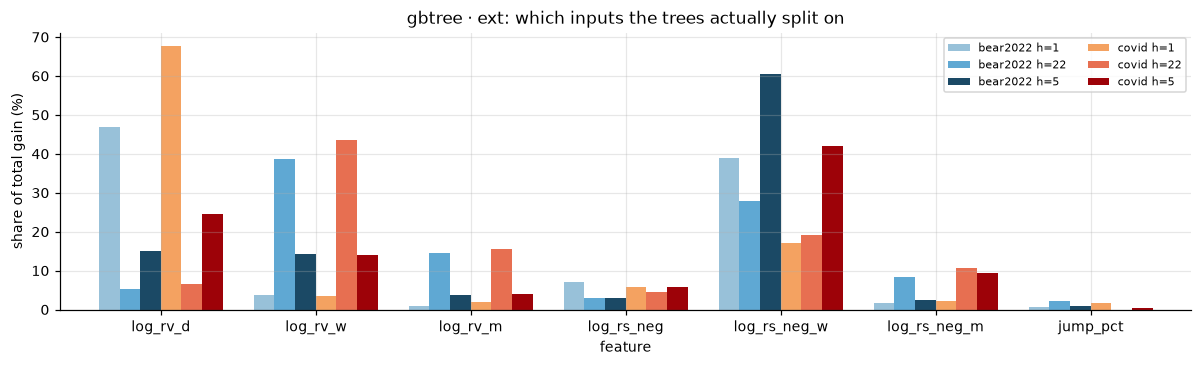

In [21]:
imp = []
for e in EVENTS:
    for h in (1, 5, 22):
        t = pd.read_csv(MODELS / "xgb" / e / f"xgb-gbtree_ext_h{h}" / "importance.csv")
        imp.append(t.assign(cell=f"{e} h={h}"))
imp = pd.concat(imp).pivot(index="feature", columns="cell", values="gain_pct").loc[adapters.FEATURE_SETS["ext"]]
fig, ax = plt.subplots(figsize=(11, 3.4))
imp.plot.bar(ax=ax, width=0.8, color=["#98c1d9", "#5fa8d3", "#1b4965", "#f4a261", "#e76f51", "#9d0208"])
ax.set_ylabel("share of total gain (%)"); ax.set_title("gbtree · ext: which inputs the trees actually split on")
plt.setp(ax.get_xticklabels(), rotation=0); ax.legend(fontsize=7, ncol=2)
fig.tight_layout()

## 10. HARNet (dilated-convolution HAR)

**Training data is different from HAR/XGBoost.** HARNet gets the **raw daily series, not the
precomputed averages**, and builds its own weekly/monthly averages with convolution layers:

* `base` (HARNet20): one channel, `rv`
* `ext` (HARNetSVJ20): three channels, `rv`, `rs_neg`, `delta_j2` (RV and RS⁻ are averaged by the convs;
  the signed jump enters only the output layer, as a daily value)
* inputs are **levels, not logs**, scaled by a fixed map x / 0.001 (no fitting, no leakage)
* the target is the level `rv_h{h}`, the loss is QLIKE
* the monthly period is **20 days, not 22** (each period must be a multiple of the previous one: 1 → 5 → 20)

**How the convolutions reproduce HAR.** Layer 1 is a 5-tap causal filter initialized to 1/5 each
(a 5-day mean). Layer 2 takes 4 taps of layer 1 spaced 5 days apart (dilation 5), each 1/4: the mean
of four weekly means = a 20-day mean. The output layer is initialized with the OLS coefficients of
that level HAR. So at iteration 0 HARNet **is** a HAR; training then lets the filter weights move
away from equal weighting (e.g. more weight on the most recent days) if that lowers validation QLIKE.

In [22]:
from volforecast.models.harnet.model import har_regressors
from volforecast.models.harnet.data import MinMaxScaler

hcfg = yaml.safe_load((PROJECT_ROOT / "configs" / "harnet.yaml").read_text(encoding="utf-8"))
sc = MinMaxScaler(hcfg["scaler"]["min"], hcfg["scaler"]["max"])
ch = hcfg["featuresets"]["ext"]["channels"]
raw = fs[ch]
x = sc.transform(raw.to_numpy())
R = pd.DataFrame(har_regressors(x, hcfg["lags"], n_avg=2, n_jump=1), index=fs.index,
                 columns=["1", "RV_t", "RS⁻_t", "RV 5-day", "RS⁻ 5-day", "RV 20-day", "RS⁻ 20-day", "ΔJ²_t"])
win = pd.concat({"raw input (decimal variance)": raw.rename(columns={"rv": "rv", "rs_neg": "rs_neg", "delta_j2": "delta_j2"}),
                 "scaled input (x / 0.001)": pd.DataFrame(x, index=fs.index, columns=ch),
                 "regressors the network builds (scaled)": R.drop(columns="1")}, axis=1)
display(Markdown("**HARNetSVJ input → internal regressors**, around the COVID sell-off"))
display(win.loc["2020-02-20":"2020-02-28"].style.format("{:.4g}"))

**HARNetSVJ input → internal regressors**, around the COVID sell-off

In [23]:
import torch
rows, kernels = [], {}
for e in EVENTS:
    for fset in ("base", "ext"):
        for h in (1, 5, 22):
            d = MODELS / "harnet" / e / f"harnet20_{fset}_h{h}"
            p, dg = rj(d / "params.json"), rj(d / "diagnostics.json")["validation"]
            rows.append({"event": e, "featureset": fset, "h": h, "variant": p["cell"]["variant"],
                         "channels": ", ".join(p["cell"]["channels"]), "best iteration": p["best_iter"],
                         "val QLIKE HARNet": dg["harnet"]["qlike"], "val QLIKE at init (=HAR)": dg["har_ols_init"]["qlike"],
                         "val QLIKE RW": dg["random_walk"]["qlike"], "refit labels": p["n_labels"]["refit"]})
            if e == "covid" and fset == "ext" and h == 5:
                state = torch.load(d / "weights.pt", weights_only=True)
                kernels = {k: v.numpy() for k, v in state.items()}
                curve = pd.read_csv(d / "val_curve.csv")
tc = hcfg["train"]
display(Markdown(f"**Training settings** (`configs/harnet.yaml`): Adam lr {tc['learning_rate']}, batches of {tc['batch_size']} "
                 f"random windows × {tc['label_length']} consecutive labels, loss {tc['loss']}, up to {tc['max_iterations']:,} "
                 f"iterations, validation every {tc['eval_every']} with patience {tc['patience_evals']} evals, "
                 f"seeds {hcfg['seeds']} (forecast = seed average), lags {hcfg['lags']}, scaler {hcfg['scaler']}"))
display(pd.DataFrame(rows).set_index(["event", "featureset", "h"]).style.format("{:.4f}", subset=pd.IndexSlice[:, ["val QLIKE HARNet", "val QLIKE at init (=HAR)", "val QLIKE RW"]]))

**Training settings** (`configs/harnet.yaml`): Adam lr 0.0001, batches of 4 random windows × 5 consecutive labels, loss QLIKE, up to 100,000 iterations, validation every 250 with patience 40 evals, seeds [42, 43, 44, 45, 46] (forecast = seed average), lags [1, 5, 20], scaler {'min': 0.0, 'max': 0.001}

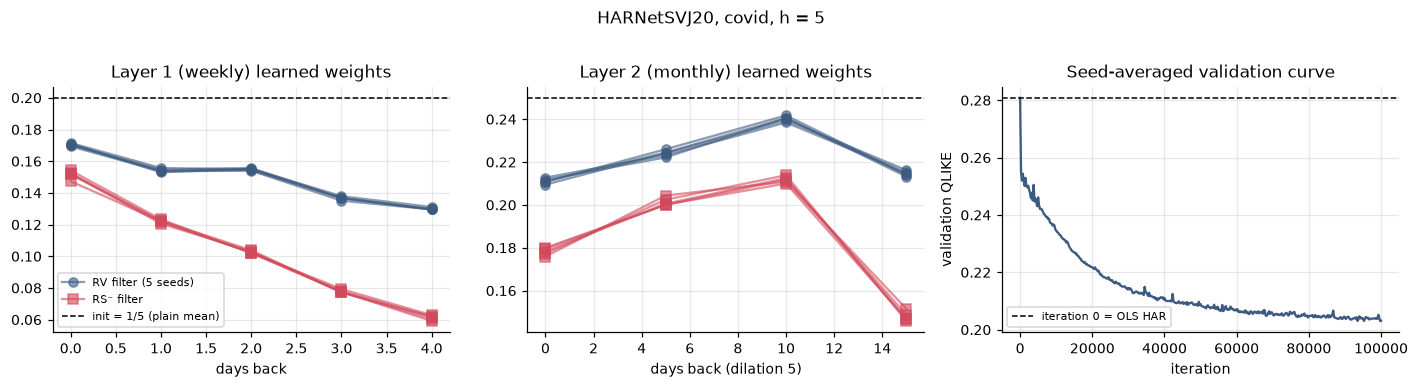

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
w1, w2 = kernels["convs.0"], kernels["convs.1"]       # (seed, out, in, kernel)
lag1 = np.arange(w1.shape[-1] - 1, -1, -1)              # tap i looks back (k-1-i) days
for s in range(w1.shape[0]):
    axes[0].plot(lag1, w1[s, 0, 0], marker="o", color=ACCENT, alpha=0.6, label="RV filter (5 seeds)" if s == 0 else None)
    axes[0].plot(lag1, w1[s, 1, 1], marker="s", color=DOWN, alpha=0.6, label="RS⁻ filter" if s == 0 else None)
axes[0].axhline(1 / 5, color="black", ls="--", lw=1, label="init = 1/5 (plain mean)")
axes[0].set_xlabel("days back"); axes[0].set_title("Layer 1 (weekly) learned weights"); axes[0].legend(fontsize=7)
lag2 = (np.arange(w2.shape[-1] - 1, -1, -1)) * 5
for s in range(w2.shape[0]):
    axes[1].plot(lag2, w2[s, 0, 0], marker="o", color=ACCENT, alpha=0.6)
    axes[1].plot(lag2, w2[s, 1, 1], marker="s", color=DOWN, alpha=0.6)
axes[1].axhline(1 / 4, color="black", ls="--", lw=1)
axes[1].set_xlabel("days back (dilation 5)"); axes[1].set_title("Layer 2 (monthly) learned weights")
axes[2].plot(curve.iteration, curve.val_qlike, color=ACCENT)
axes[2].axhline(curve.val_qlike.iloc[0], color="black", ls="--", lw=1, label="iteration 0 = OLS HAR")
axes[2].set_xlabel("iteration"); axes[2].set_ylabel("validation QLIKE"); axes[2].legend(fontsize=7)
axes[2].set_title("Seed-averaged validation curve")
fig.suptitle("HARNetSVJ20, covid, h = 5", y=1.02)
fig.tight_layout()

**What training changed.** All five seeds agree closely, so this is signal, not noise. The weekly
filters moved from a flat 1/5 to **declining weights**: the most recent days count more, much more so
for RS⁻ (yesterday's downside matters, week-old downside barely does). This is a recency-weighted
average that a fixed HAR cannot express. Weights that sum to less than 1 are absorbed by the output
layer. Validation QLIKE fell from the HAR starting point (≈ 0.281) to ≈ 0.203, and the best iteration
was close to the 100,000 cap.

## 11. Mamba and the LSTM control

**Training data is a sliding window of raw daily values**, with no weekly/monthly averages at all, so
the network must learn its own memory:

* `base`: one channel, `log_rv_d`
* `ext`: three channels, `log_rv_d`, `log_rs_neg`, `jump_pct` (the daily versions of the `ext` features)
* each channel standardized with its training-block mean and std
* one sample = the last L days of inputs, L ∈ {22, 66, 126} chosen on validation per cell; target
  `y_h{h}`, MSE loss, smearing afterwards (as HAR/XGBoost)

Architecture: `Linear(C→16)` → 2-layer Mamba (selective state space) or LSTM, hidden 16 → last step →
`Linear(16→1)`. Mamba's last hidden state is RMS-normalized and the LSTM's is tanh-bounded, so, like
trees, both have a ceiling on what they can forecast.

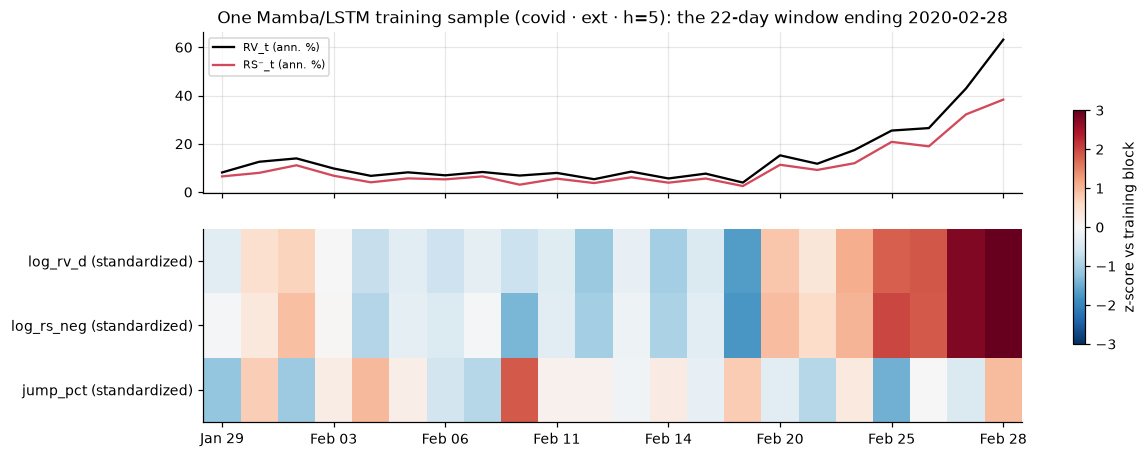

target for this sample: y_h5 = -7.224  (= 43% ann. vol over the next 5 days)


,training mean,training std
log_rv_d,-10.1945,1.0728
log_rs_neg,-10.9395,1.1334
jump_pct,-0.0197,0.2655


In [25]:
from volforecast.models.seq.data import build_seq_data
scfg = yaml.safe_load((PROJECT_ROOT / "configs" / "seq.yaml").read_text(encoding="utf-8"))
p = rj(MODELS / "seq" / "covid" / "mamba_ext_h5" / "params.json")
L = p["chosen"]["lookback"]
sd = build_seq_data(features, splits["covid"], scfg["featuresets"]["ext"], 5, max(scfg["tuning"]["lookback"]))
T = pd.Timestamp("2020-02-28"); t = sd.dates.get_loc(T)
win = sd.windows(np.array([t]), L)[0]                   # (L, C) standardized
raw = features.set_index("date").iloc[t - L + 1: t + 1][scfg["featuresets"]["ext"]]

fig, axes = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, height_ratios=[1, 1.2])
axes[0].plot(range(L), ann_vol(np.exp(raw.log_rv_d)), color="black", label="RV_t (ann. %)")
axes[0].plot(range(L), ann_vol(np.exp(raw.log_rs_neg)), color=DOWN, label="RS⁻_t (ann. %)")
axes[0].legend(fontsize=7); axes[0].set_title(f"One Mamba/LSTM training sample (covid · ext · h=5): the {L}-day window ending {T.date()}")
im = axes[1].imshow(win.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
axes[1].set_yticks(range(len(sd.channels)), [f"{c} (standardized)" for c in sd.channels])
axes[1].set_xticks(range(0, L, 3), [d.strftime("%b %d") for d in raw.index[::3]])
axes[1].grid(False)
fig.colorbar(im, ax=axes, shrink=0.6, label="z-score vs training block")
plt.show()
print(f"target for this sample: y_h5 = {sd.y[t]:.3f}  (= {ann_vol(np.exp(sd.y[t])):.0f}% ann. vol over the next 5 days)")
display(pd.DataFrame({"training mean": sd.mean, "training std": sd.std}, index=sd.channels))

In [26]:
rows = []
for e in EVENTS:
    for arch in ("mamba", "lstm"):
        for fset in ("base", "ext"):
            for h in (1, 5, 22):
                d = MODELS / "seq" / e / f"{arch}_{fset}_h{h}"
                if not (d / "params.json").exists():
                    continue
                p = rj(d / "params.json")
                rows.append({"event": e, "arch": arch, "featureset": fset, "h": h,
                             "lookback L (chosen)": p["chosen"]["lookback"], "lr": p["chosen"]["learning_rate"],
                             "best epochs per seed": str(p["best_epochs"]),
                             "val MSE (log)": p["val"]["mse_log"], "val MSE RW": p["val"]["mse_log_naive"],
                             "val QLIKE": p["val"]["qlike"], "smearing S": p["smear"]["S"],
                             "ceiling (ann. %, max over seeds)": float(ann_vol(np.exp(max(p["ceiling_log_per_seed"])))),
                             "device": p["device"]})
tc = scfg["train"]
display(Markdown(f"**Training settings** (`configs/seq.yaml`): model {scfg['model']}, AdamW, batch {tc['batch_size']}, "
                 f"≤{tc['max_epochs']} epochs, early stopping patience {tc['patience']}, grad clip {tc['grad_clip']}, "
                 f"lookback grid {scfg['tuning']['lookback']}, seeds {scfg['seeds']}"))
display(pd.DataFrame(rows).set_index(["event", "arch", "featureset", "h"]).style.format(
    {"val MSE (log)": "{:.3f}", "val MSE RW": "{:.3f}", "val QLIKE": "{:.3f}", "smearing S": "{:.3f}",
     "ceiling (ann. %, max over seeds)": "{:.0f}"}))

**Training settings** (`configs/seq.yaml`): model {'hidden_size': 16, 'num_layers': 2, 'mamba': {'state_size': 16, 'expand': 2, 'conv_kernel': 4}}, AdamW, batch 256, ≤150 epochs, early stopping patience 15, grad clip 1.0, lookback grid [22, 66, 126], seeds [42, 43, 44, 45, 46]

The *ceiling* column is the highest forecast each frozen network can produce whatever its inputs
(converted to annualized vol, before smearing). If a crash pushes realized vol above it, the model
cannot follow, the same issue as for tree ensembles.

## 12. One day, six models: exactly what goes in

Origin **2020-02-21** (the last calm close before the COVID sell-off), `ext` versions, h = 5.

In [27]:
T = pd.Timestamp("2020-02-21"); r = fs.loc[T]
L = rj(MODELS / "seq" / "covid" / "mamba_ext_h5" / "params.json")["chosen"]["lookback"]
summary = pd.DataFrame([
    ["GARCH", "every daily return 2004-01-02 → today, 1 channel", f"ret_cc_pct_t = {r.ret_cc_pct:+.3f} %  (plus σ²_t carried by the recursion)",
     "none (likelihood of returns)", "Student-t ML, no tuning"],
    ["HAR", "7 numbers for day t", ", ".join(f"{c}={r[c]:.2f}" for c in adapters.FEATURE_SETS["ext"]),
     f"y_h5 = {r.y_h5:.2f}", "OLS + smearing"],
    ["XGBoost", "same 7 numbers as HAR", "(identical to HAR)", f"y_h5 = {r.y_h5:.2f}", "100 TPE trials, 5 seeds (trees)"],
    ["HARNet", "raw levels over the last 20 days, 3 channels", f"rv, rs_neg, delta_j2 /0.001 → today {r.rv/1e-3:.3f}, {r.rs_neg/1e-3:.3f}, {r.delta_j2/1e-3:+.3f}",
     f"rv_h5 = {r.rv_h5:.2e}", "QLIKE, Adam, OLS-HAR init, 5 seeds"],
    ["Mamba / LSTM", f"last {L} days (covid ext h5), 3 channels, standardized", f"log_rv_d, log_rs_neg, jump_pct today = {r.log_rv_d:.2f}, {r.log_rs_neg:.2f}, {r.jump_pct:+.2f}",
     f"y_h5 = {r.y_h5:.2f}", "MSE, AdamW, lookback tuned, 5 seeds"],
], columns=["model", "input shape", "values on 2020-02-21", "training target", "fitting"]).set_index("model")
display(summary)

,input shape,values on 2020-02-21,training target,fitting
model,,,,
GARCH,"every daily return 2004-01-02 → today, 1 channel",ret_cc_pct_t = -1.035 % (plus σ²_t carried by...,none (likelihood of returns),"Student-t ML, no tuning"
HAR,7 numbers for day t,"log_rv_d=-9.81, log_rv_w=-10.18, log_rv_m=-10....",y_h5 = -7.43,OLS + smearing
XGBoost,same 7 numbers as HAR,(identical to HAR),y_h5 = -7.43,"100 TPE trials, 5 seeds (trees)"
HARNet,"raw levels over the last 20 days, 3 channels","rv, rs_neg, delta_j2 /0.001 → today 0.055, 0.0...",rv_h5 = 5.94e-04,"QLIKE, Adam, OLS-HAR init, 5 seeds"
Mamba / LSTM,"last 22 days (covid ext h5), 3 channels, stand...","log_rv_d, log_rs_neg, jump_pct today = -9.81, ...",y_h5 = -7.43,"MSE, AdamW, lookback tuned, 5 seeds"


**In one sentence each**

* **GARCH** infers today's variance from the size of past daily returns and lets it decay toward a
  long-run level. Only returns, no intraday data, no direction.
* **HAR** is a linear regression of future log RV on hand-made 1/5/22-day averages (plus downside and
  jump terms in `ext`).
* **XGBoost** sees the same hand-made averages as HAR but can learn non-linear thresholds; tree
  forecasts are bounded by the training range.
* **HARNet** sees raw daily levels and *learns* the averaging weights, starting from exactly HAR.
* **Mamba / LSTM** see raw daily logs over a long window and must learn both the averaging and the
  memory from scratch.